# 03. AutoML 비교 실험 (가산점)

**목적:** 직접 설계한 특성 공학 파이프라인(02 노트북)과 AutoML(FLAML)의 성능·비용을 비교한다.

**실험 설계** (02 노트북과 동일한 train 712 / test 179 분할, Stratified 5-Fold CV, F1 기준)
- **AutoML-Raw**: 원본 컬럼 7개(Pclass, Sex, Age, SibSp, Parch, Fare, Embarked)만 입력. 결측치·범주형 처리와 모델·하이퍼파라미터 선택을 모두 AutoML에 맡김
- **AutoML-FE**: 원본 7개 + 직접 만든 파생 변수 6개(FamilySize, IsAlone, FarePerPerson, HasCabin, Title, AgeGroup)를 입력
- 비교 대상: 수동 파이프라인 Exp-3 + XGBoost(필수 실험 CV 최고), GridSearchCV 튜닝 모델 3종

재현성을 위해 시간 제한 대신 **시도 횟수(max_iter=300)와 seed=42를 고정**한다(시간 제한을 쓰면 컴퓨터 속도에 따라 결과가 달라짐).

In [1]:
import sys, os, time, warnings, logging
sys.path.append(os.path.abspath(".."))
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from flaml import AutoML
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from src.fe_pipeline import add_features, RANDOM_STATE, TARGET, AGE_BINS

logging.getLogger("flaml.automl.logger").setLevel(logging.WARNING)
FIG, RES = "../results/figures", "../results"
sns.set_theme(style="whitegrid")

df = add_features(pd.read_csv("../data/train.csv"))
df["AgeGroup"] = pd.cut(df["Age"], bins=AGE_BINS, labels=False, right=False)   # 결측은 NaN 그대로 (AutoML이 처리)
X, y = df.drop(columns=[TARGET]), df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

RAW = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]
FE = RAW + ["FamilySize", "IsAlone", "FarePerPerson", "HasCabin", "Title", "AgeGroup"]


def prep(d, cols):
    """AutoML 입력: 문자열 컬럼만 category 타입으로 지정 (결측·인코딩은 AutoML이 처리)"""
    d = d[cols].copy()
    for c in d.select_dtypes(include=["object", "string"]).columns:
        d[c] = d[c].astype("category")
    return d


def test_scores(pred, proba):
    return {"test_accuracy": accuracy_score(y_test, pred), "test_precision": precision_score(y_test, pred),
            "test_recall": recall_score(y_test, pred), "test_f1": f1_score(y_test, pred),
            "test_roc_auc": roc_auc_score(y_test, proba)}

## AutoML 실행 (FLAML)

In [2]:
rows, automls = [], {}
for name, cols in [("AutoML-Raw", RAW), ("AutoML-FE", FE)]:
    automl = AutoML()
    t0 = time.time()
    automl.fit(prep(X_train, cols), y_train, task="classification", metric="f1",
               eval_method="cv", split_type=CV, time_budget=-1, max_iter=300,
               estimator_list=["lgbm", "xgboost", "rf", "extra_tree", "lrl1"],
               seed=RANDOM_STATE, n_jobs=1, verbose=0)
    sec = time.time() - t0
    automls[name] = automl
    Xt = prep(X_test, cols)
    r = {"method": name, "n_input_cols": len(cols), "best_estimator": automl.best_estimator,
         "cv_f1": 1 - automl.best_loss, "n_trials": 300, "sec": round(sec, 1)}
    r.update(test_scores(automl.predict(Xt), automl.predict_proba(Xt)[:, 1]))
    rows.append(r)
    print(f"{name}: best={automl.best_estimator}, CV F1={1-automl.best_loss:.4f}, {sec:.0f}s")
    print("  best config:", automl.best_config)

AutoML-Raw: best=lgbm, CV F1=0.7741, 20s
  best config: {'n_estimators': 117, 'num_leaves': 6, 'min_child_samples': 43, 'learning_rate': np.float64(0.7625911937126283), 'log_max_bin': 8, 'colsample_bytree': 1.0, 'reg_alpha': np.float64(0.012144846567324645), 'reg_lambda': np.float64(0.004261794425062402)}


AutoML-FE: best=lgbm, CV F1=0.7875, 18s
  best config: {'n_estimators': 6, 'num_leaves': 12, 'min_child_samples': 13, 'learning_rate': np.float64(0.8159471686210248), 'log_max_bin': 3, 'colsample_bytree': np.float64(0.940521175695079), 'reg_alpha': np.float64(0.0011499439211760756), 'reg_lambda': np.float64(3.1748705602033276)}


## 수동 파이프라인 결과와 비교
수동 파이프라인과 GridSearchCV 결과는 02 노트북에서 저장한 값을 그대로 불러와 보고서 수치와 일치시킨다.

In [3]:
main = pd.read_csv(f"{RES}/main_comparison.csv")
for exp, m in [("Exp-3", "XGBoost"), ("Exp-1", "LogReg")]:
    r = main[(main.experiment == exp) & (main.model == m)].iloc[0]
    rows.append({"method": f"Manual {exp} + {m}", "n_input_cols": 14, "best_estimator": m, "cv_f1": r.f1,
                 "n_trials": 1, "sec": np.nan, "test_accuracy": r.test_accuracy, "test_precision": np.nan,
                 "test_recall": np.nan, "test_f1": r.test_f1, "test_roc_auc": r.test_roc_auc})

gs = pd.read_csv(f"{RES}/gridsearch_results.csv")
for g in gs.itertuples():
    rows.append({"method": f"GridSearchCV {g.model}", "n_input_cols": 14, "best_estimator": g.model,
                 "cv_f1": g.best_cv_f1, "n_trials": g.n_candidates, "sec": g.sec,
                 "test_accuracy": g.test_accuracy, "test_precision": g.test_precision, "test_recall": g.test_recall,
                 "test_f1": g.test_f1, "test_roc_auc": g.test_roc_auc})

cmp = pd.DataFrame(rows)
cmp.round(4).to_csv(f"{RES}/automl_comparison.csv", index=False)
cmp.round(4)

,method,n_input_cols,best_estimator,cv_f1,n_trials,sec,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
0,AutoML-Raw,7,lgbm,0.7741,300,19.8,0.7765,0.7377,0.6522,0.6923,0.8134
1,AutoML-FE,13,lgbm,0.7875,300,17.8,0.7989,0.7619,0.6957,0.7273,0.8491
2,Manual Exp-3 + XGBoost,14,XGBoost,0.7794,1,NaN,0.7989,NaN,NaN,0.7353,0.8305
3,Manual Exp-1 + LogReg,14,LogReg,0.7639,1,NaN,0.8324,NaN,NaN,0.7761,0.8731
4,GridSearchCV RandomForest,14,RandomForest,0.7939,72,90.7,0.7877,0.7541,0.6667,0.7077,0.8456
5,GridSearchCV XGBoost,14,XGBoost,0.7790,96,69.8,0.8101,0.7612,0.7391,0.7500,0.8322
6,GridSearchCV LogReg,14,LogReg,0.7697,48,30.8,0.8156,0.7812,0.7246,0.7519,0.8610


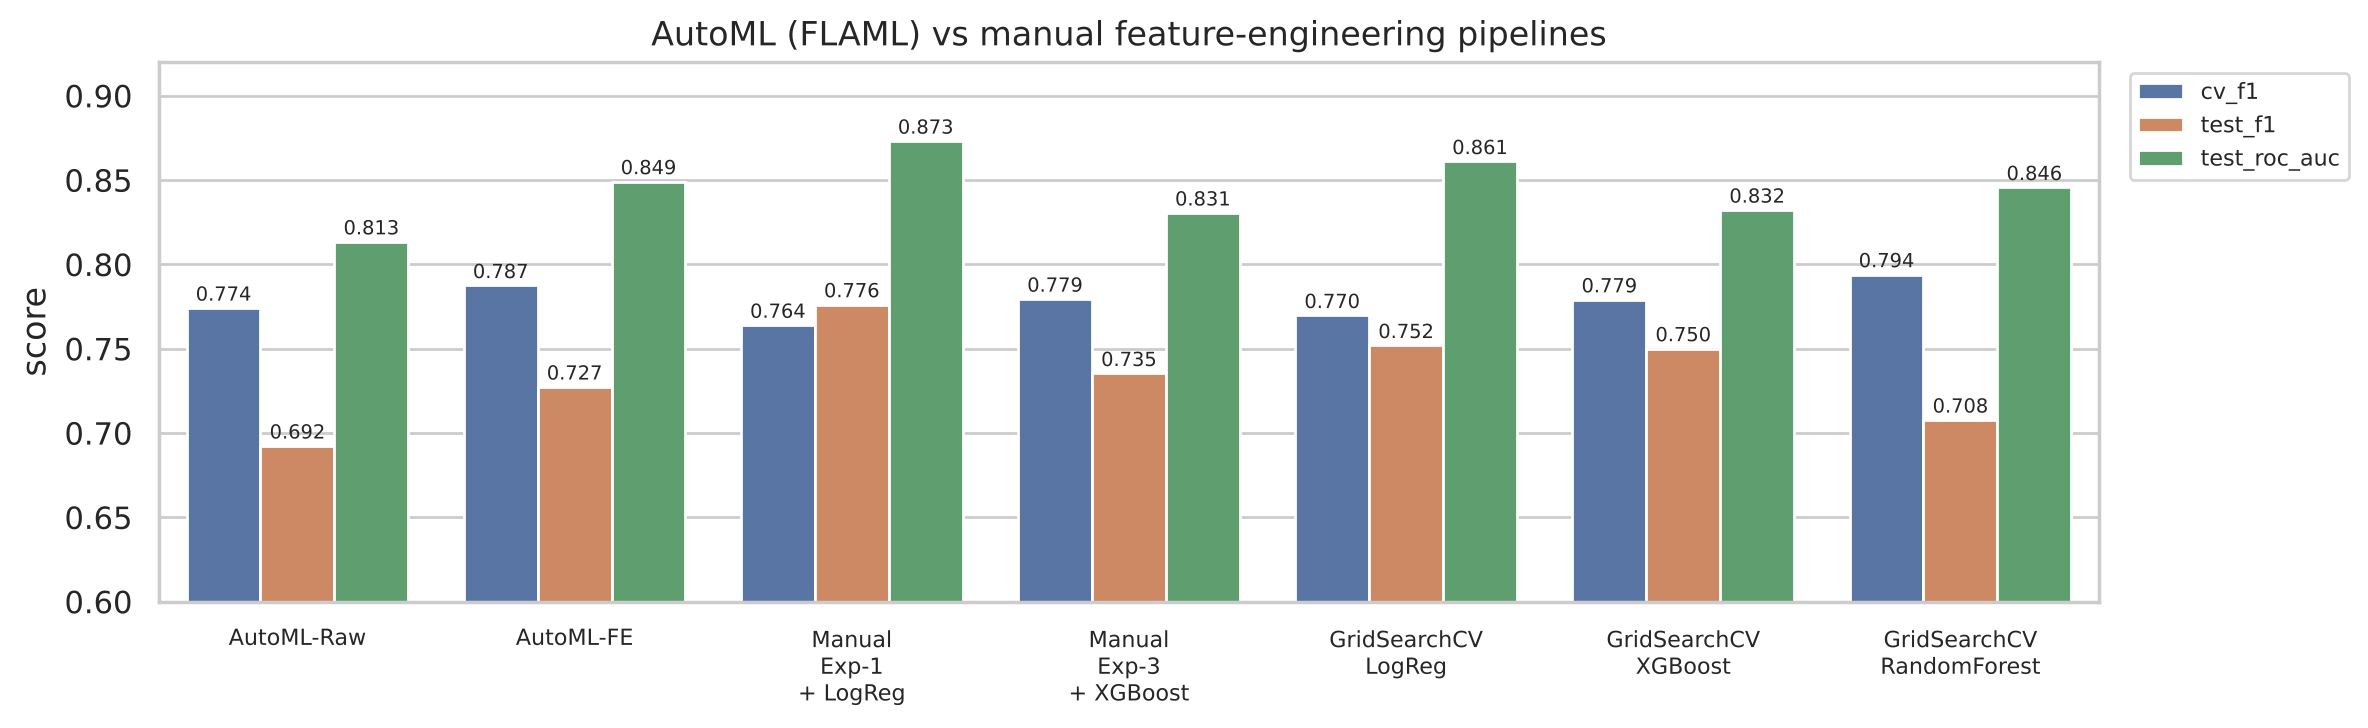

In [4]:
order = ["AutoML-Raw", "AutoML-FE", "Manual Exp-1 + LogReg", "Manual Exp-3 + XGBoost",
         "GridSearchCV LogReg", "GridSearchCV XGBoost", "GridSearchCV RandomForest"]
plot = cmp.set_index("method").loc[order, ["cv_f1", "test_f1", "test_roc_auc"]].reset_index().melt(
    id_vars="method", var_name="metric", value_name="score")
fig, ax = plt.subplots(figsize=(12, 3.8))
sns.barplot(data=plot, x="method", y="score", hue="metric", ax=ax)
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=7, padding=1)
ax.set_ylim(0.6, 0.92); ax.set_xlabel(""); ax.set_title("AutoML (FLAML) vs manual feature-engineering pipelines")
ax.set_xticks(range(len(order)), [o.replace(" + ", "\n+ ").replace("GridSearchCV ", "GridSearchCV\n").replace("Manual ", "Manual\n") for o in order], fontsize=8); ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
plt.tight_layout(); plt.savefig(f"{FIG}/60_automl_comparison.png", dpi=150); plt.show()

## AutoML이 탐색한 모델 분포

In [5]:
hist = []
for name, a in automls.items():
    for est, loss in a.best_loss_per_estimator.items():
        if loss is not None and np.isfinite(loss):
            hist.append({"run": name, "estimator": est, "best_cv_f1": 1 - loss})
hist = pd.DataFrame(hist)
hist.round(4).to_csv(f"{RES}/automl_estimators.csv", index=False)
print(hist.pivot(index="estimator", columns="run", values="best_cv_f1").round(4))

run         AutoML-FE  AutoML-Raw
estimator                        
extra_tree     0.7339      0.7261
lgbm           0.7875      0.7741
lrl1           0.4521      0.4608
rf             0.7827      0.7444
xgboost        0.7832      0.7647
